# EN3150: Pattern Recognition & Machine Learning
## Assignment 03: Resource-Constrained CNN for Edge Image Classification
### Model A: Standard Convolutional Neural Network (CNN)

---

### Project Overview & Objectives
This notebook develops and evaluates **Model A**, a standard convolutional neural network designed for edge-device deployment on the German Traffic Sign Recognition Benchmark (GTSRB).

**Key Specifications & Constraints:**
- **Input Resolution:** Downscaled to $64 \times 64$ pixels to emulate a resource-constrained edge sensor environment.
- **Dataset Partitioning:** 70% Training, 15% Validation, and 15% Testing with strictly disjoint splits.
- **Architecture:** Interleaved standard 2D convolutions (`Conv2d`), ReLU activations, and max-pooling (`MaxPool2d`) layers.
- **Parameter Budget:** Sub-100k trainable parameters (Model A achieves 45,643 parameters).
- **Hardware-Aware Design Justification:**
  - Uses **ReLU** activation: Eliminates computationally expensive transcendental operations (like exponential calculations in Sigmoid/Tanh), optimizing inference latency on embedded CPUs/MCUs.
- **Training Setup:** Trained for 20 epochs using Cross-Entropy Loss and the Adam optimizer.

## 1. Data Preparation and Preprocessing

In this section:
1. Traffic sign images are resized to $64 \times 64$ pixels.
2. Training data is augmented with color jitter and slight rotation to improve model generalization.
3. Images are normalized to $[-1, 1]$ using standard channel transforms.
4. The dataset is split into training (70%), validation (15%), and testing (15%) subsets with a fixed generator seed (`seed=42`) for reproducibility.
5. PyTorch `DataLoader` instances are prepared for batch training and evaluation.

In [1]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Dataset


train_transforms = transforms.Compose(
    [
        transforms.Resize((64, 64)),
        transforms.ColorJitter(brightness=0.2),
        transforms.RandomRotation(10),
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,)),
    ]
)

eval_transforms = transforms.Compose(
    [
        transforms.Resize((64, 64)),
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,)),
    ]
)


raw_dataset = datasets.GTSRB(root="./data", split="train", download=True)


total_size = len(raw_dataset)
train_size = int(0.70 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size


generator = torch.Generator().manual_seed(42)
train_subset, val_subset, test_subset = random_split(
    raw_dataset, [train_size, val_size, test_size], generator=generator
)


class SubsetWrapper(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        image, label = self.subset[index]
        if self.transform:
            image = self.transform(image)
        return image, label

    def __len__(self):
        return len(self.subset)


train_data = SubsetWrapper(train_subset, transform=train_transforms)
val_data = SubsetWrapper(val_subset, transform=eval_transforms)
test_data = SubsetWrapper(test_subset, transform=eval_transforms)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

print(
    f"Data pipeline ready! Train: {len(train_data)}, Val: {len(val_data)}, Test: {len(test_data)}"
)

Data pipeline ready! Train: 18648, Val: 3996, Test: 3996


## 2. Dataset Verification and Exploratory Data Analysis

### 2.1 Split Disjointness and Size Verification
Verifying that the split proportions strictly match 70% / 15% / 15% and confirming that the indices across all three splits are mutually disjoint to prevent data leakage.

In [2]:
from collections import Counter

expected_total = len(raw_dataset)
actual_total = len(train_data) + len(val_data) + len(test_data)
print(f"Raw images: {expected_total:,}")
print(
    f"Train / validation / test: {len(train_data):,} / {len(val_data):,} / {len(test_data):,}"
)
print(f"Split totals match: {actual_total == expected_total}")
print(
    f"Split proportions: train={len(train_data)/actual_total:.1%}, validation={len(val_data)/actual_total:.1%}, test={len(test_data)/actual_total:.1%}"
)
assert actual_total == expected_total
assert len(set(train_subset.indices) & set(val_subset.indices)) == 0
assert len(set(train_subset.indices) & set(test_subset.indices)) == 0
assert len(set(val_subset.indices) & set(test_subset.indices)) == 0
print("Splits are disjoint.")

Raw images: 26,640
Train / validation / test: 18,648 / 3,996 / 3,996
Split totals match: True
Split proportions: train=70.0%, validation=15.0%, test=15.0%
Splits are disjoint.


### 2.2 Class Distribution Across Splits
Inspecting class representation across all 43 GTSRB categories in the training, validation, and test subsets to verify balanced split distribution.

In [3]:
def class_counts(dataset):
    counts = Counter()
    for _, label in dataset:
        counts[int(label)] += 1
    return counts


train_counts = class_counts(train_subset)
val_counts = class_counts(val_subset)
test_counts = class_counts(test_subset)
print(
    f"Classes represented (train/validation/test): {len(train_counts)} / {len(val_counts)} / {len(test_counts)}"
)
print("Class | Train | Validation | Test")
for class_id in range(43):
    print(
        f"{class_id:>5} | {train_counts[class_id]:>5} | {val_counts[class_id]:>10} | {test_counts[class_id]:>4}"
    )

Classes represented (train/validation/test): 43 / 43 / 43
Class | Train | Validation | Test
    0 |   117 |         14 |   19
    1 |  1051 |        226 |  223
    2 |  1029 |        238 |  233
    3 |   674 |        138 |  148
    4 |   910 |        189 |  221
    5 |   866 |        185 |  209
    6 |   221 |         32 |   47
    7 |   669 |        136 |  155
    8 |   678 |        138 |  144
    9 |   692 |        143 |  155
   10 |   929 |        224 |  197
   11 |   627 |        134 |  139
   12 |   987 |        210 |  213
   13 |  1015 |        212 |  213
   14 |   381 |         81 |   78
   15 |   286 |         52 |   82
   16 |   222 |         44 |   34
   17 |   525 |        130 |   95
   18 |   591 |        113 |  106
   19 |   101 |         24 |   25
   20 |   163 |         38 |   39
   21 |   180 |         25 |   35
   22 |   201 |         31 |   38
   23 |   257 |         59 |   44
   24 |   125 |         28 |   27
   25 |   721 |        151 |  148
   26 |   281 |         

### 2.3 DataLoader Batch Verification
Inspecting the first batch from `train_loader` to verify tensor shapes, dimensions $(B, C, H, W) = (32, 3, 64, 64)$, value ranges, and labels integrity.

In [4]:
images, labels = next(iter(train_loader))
print(f"Image batch shape: {tuple(images.shape)}")
print(f"Label batch shape: {tuple(labels.shape)}")
print(f"Image values: min={images.min().item():.3f}, max={images.max().item():.3f}")
print(f"Labels in this batch: {sorted(labels.unique().tolist())}")
assert images.ndim == 4 and images.shape[1:] == (3, 64, 64)
assert labels.ndim == 1 and images.shape[0] == labels.shape[0]
assert torch.isfinite(images).all()
assert labels.min() >= 0 and labels.max() < 43
print("Batch checks passed.")

Image batch shape: (32, 3, 64, 64)
Label batch shape: (32,)
Image values: min=-1.000, max=1.000
Labels in this batch: [0, 1, 3, 6, 7, 8, 9, 13, 14, 15, 23, 25, 29, 31, 32, 33, 34, 38, 39, 40]
Batch checks passed.


### 2.4 Sample Image Visualizations
Visualizing a sample batch of transformed input images alongside their ground-truth class labels.

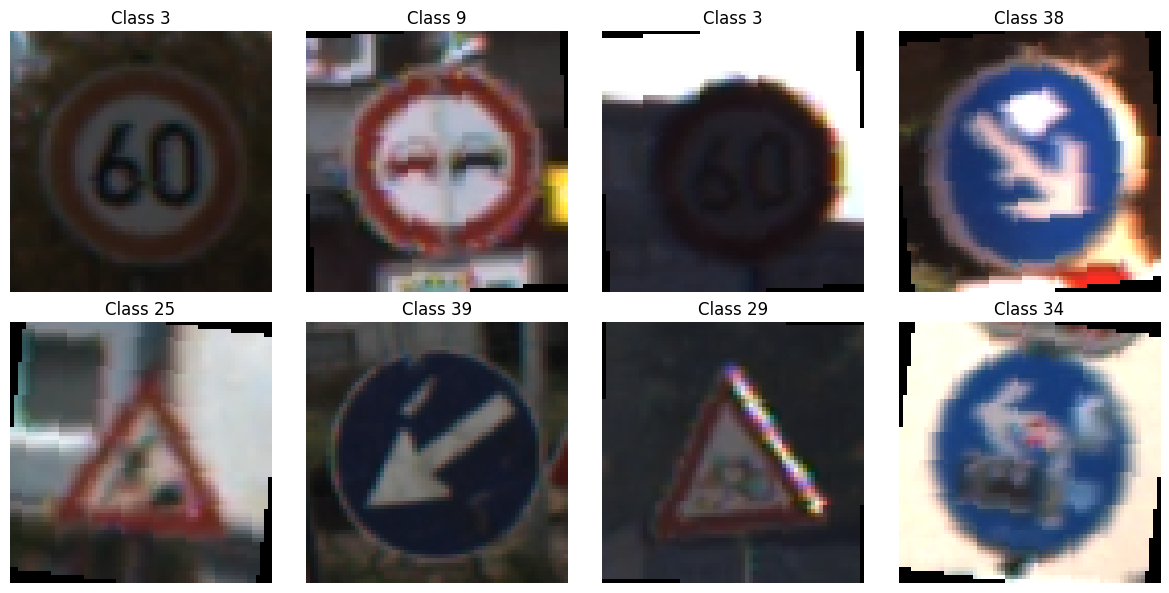

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, label in zip(axes.flat, images[:8], labels[:8]):
    display_image = image.permute(1, 2, 0).cpu() * 0.5 + 0.5
    ax.imshow(display_image.clamp(0, 1))
    ax.set_title(f"Class {label.item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Custom Architecture Design: Model A (Standard CNN)

### Architectural Specification:
- **Feature Extractor:** 4 convolutional blocks interleaving standard `Conv2d` ($3 \times 3$ kernel, stride 1, padding 1) and `MaxPool2d` ($2 \times 2$, stride 2).
  - Channel progression: $3 \rightarrow 16 \rightarrow 32 \rightarrow 32 \rightarrow 32$
  - Spatial resolution: $64 \times 64 \rightarrow 32 \times 32 \rightarrow 16 \times 16 \rightarrow 8 \times 8 \rightarrow 4 \times 4$
- **Classifier:** `Flatten()` followed by a single linear projection layer (`Linear(512, 43)`).
- **Activation:** **ReLU** across all convolutional stages (hardware-friendly, avoiding exponentials).
- **Total Trainable Parameters:** 45,643 parameters (strictly under the 100k edge constraint).

In [6]:
import torch.nn as nn


class ModelA(nn.Module):
    def __init__(self, num_classes=43):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(512, num_classes))

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model_a = ModelA()


total_params = sum(p.numel() for p in model_a.parameters() if p.requires_grad)
print(f"Total Trainable Parameters: {total_params}")

Total Trainable Parameters: 45643


### 3.1 Model Forward Pass Verification
Validating that a batch of input images passes correctly through the network and produces logits of shape $(32, 43)$ without numerical anomalies (NaNs or Infs).

In [7]:
model_a.eval()
with torch.inference_mode():
    logits = model_a(images)

trainable_params = sum(
    parameter.numel() for parameter in model_a.parameters() if parameter.requires_grad
)
print(f"Model output shape: {tuple(logits.shape)}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"All output values finite: {torch.isfinite(logits).all().item()}")
assert logits.shape == (images.shape[0], 43)
assert torch.isfinite(logits).all()
print("Model forward-pass checks passed.")

Model output shape: (32, 43)
Trainable parameters: 45,643
All output values finite: True
Model forward-pass checks passed.


## 4. Model Training

- **Loss Function:** `nn.CrossEntropyLoss()`
- **Optimizer:** Adam with learning rate $\eta = 0.001$.
- **Epochs:** 20 epochs (as specified in the assignment).
- **Device:** Automatic GPU acceleration via CUDA if available, falling back to CPU.
- **Metrics Tracked:** Training loss, training accuracy, validation loss, and validation accuracy recorded across each epoch.

In [8]:
import torch.optim as optim

# 1. Define Loss Function and Optimizer
criterion = nn.CrossEntropyLoss()
# Adam is the safe default for Model A, as Member 3 handles the optimizer comparisons later
optimizer = optim.Adam(model_a.parameters(), lr=0.001)

# Hardware acceleration check (uses GPU if available, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_a.to(device)
print(f"Training on device: {device}")

# Arrays to store metrics for exporting the required matplotlib curves later
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

# The assignment strictly requires training for at least 20 epochs
epochs = 20

for epoch in range(epochs):
    # --- TRAINING PHASE ---
    model_a.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # Zero the gradients, perform forward pass, calculate loss, and update weights
        optimizer.zero_grad()
        outputs = model_a(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # Track training metrics
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / len(train_loader.dataset)
    epoch_train_acc = correct / total
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # --- VALIDATION PHASE ---
    model_a.eval()
    val_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():  # Disable gradient calculation during validation
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_a(images)
            loss = criterion(outputs, labels)

            # Track validation metrics
            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_val_acc = correct / total
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.4f}"
    )

Training on device: cpu
Epoch 01/20 | Train Loss: 2.4712 | Train Acc: 0.2987 | Val Loss: 1.4478 | Val Acc: 0.5348
Epoch 02/20 | Train Loss: 1.1207 | Train Acc: 0.6379 | Val Loss: 0.8453 | Val Acc: 0.7165
Epoch 03/20 | Train Loss: 0.5822 | Train Acc: 0.8124 | Val Loss: 0.4149 | Val Acc: 0.8701
Epoch 04/20 | Train Loss: 0.3361 | Train Acc: 0.8917 | Val Loss: 0.2532 | Val Acc: 0.9269
Epoch 05/20 | Train Loss: 0.2329 | Train Acc: 0.9258 | Val Loss: 0.2173 | Val Acc: 0.9317
Epoch 06/20 | Train Loss: 0.1703 | Train Acc: 0.9469 | Val Loss: 0.1616 | Val Acc: 0.9505
Epoch 07/20 | Train Loss: 0.1345 | Train Acc: 0.9566 | Val Loss: 0.1187 | Val Acc: 0.9645
Epoch 08/20 | Train Loss: 0.1100 | Train Acc: 0.9642 | Val Loss: 0.1113 | Val Acc: 0.9655
Epoch 09/20 | Train Loss: 0.1038 | Train Acc: 0.9666 | Val Loss: 0.0785 | Val Acc: 0.9752
Epoch 10/20 | Train Loss: 0.0801 | Train Acc: 0.9740 | Val Loss: 0.1080 | Val Acc: 0.9655
Epoch 11/20 | Train Loss: 0.0766 | Train Acc: 0.9743 | Val Loss: 0.0893 | Va

## 5. Model Evaluation and Performance Metrics

Evaluating Model A on the held-out test set:
1. **Loss Curves:** Plotting training vs. validation loss over 20 epochs to assess convergence and overfitting.
2. **Classification Report:** Detailed evaluation showing Precision, Recall, and F1-score across all 43 classes.
3. **Confusion Matrix:** Generating and saving `model_a_confusion_matrix.png`.
4. **Weights Export:** Saving trained weights to `model_a_weights.pth` for downstream edge hardware profiling and quantization.

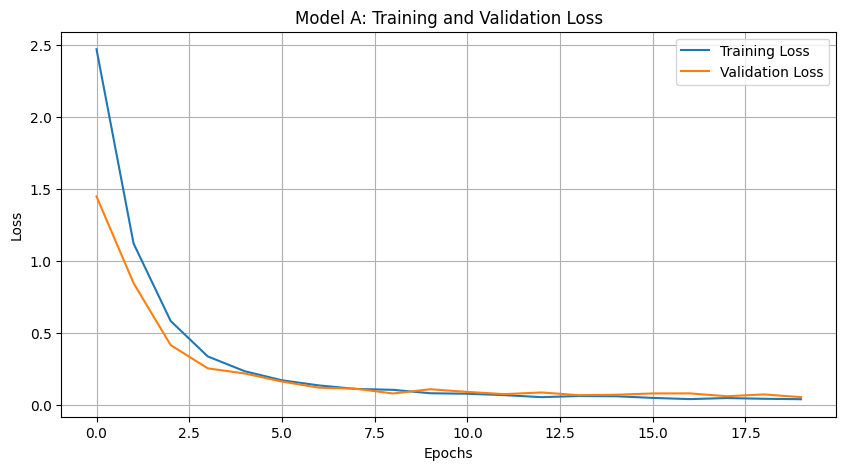


--- Classification Report (Precision, Recall, Accuracy) ---
              precision    recall  f1-score   support

           0       0.90      1.00      0.95        19
           1       0.98      0.98      0.98       223
           2       0.99      1.00      0.99       233
           3       0.98      0.99      0.99       148
           4       0.99      0.97      0.98       221
           5       0.98      0.99      0.98       209
           6       1.00      1.00      1.00        47
           7       0.99      0.95      0.97       155
           8       0.99      1.00      0.99       144
           9       0.99      0.99      0.99       155
          10       0.99      1.00      1.00       197
          11       0.99      0.99      0.99       139
          12       1.00      1.00      1.00       213
          13       1.00      1.00      1.00       213
          14       1.00      1.00      1.00        78
          15       1.00      0.99      0.99        82
          16       1

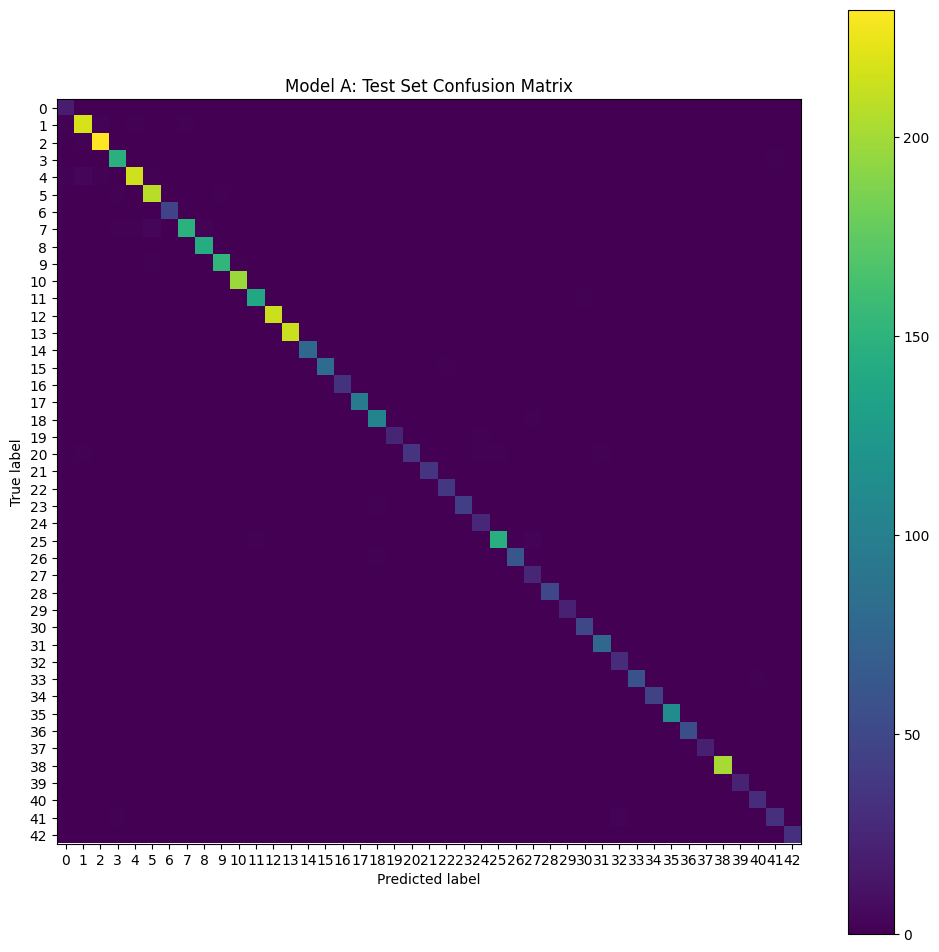


Model saved to 'model_a_weights.pth'. Share this file with Member 4.


In [9]:
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# 1. Plot and Save the Loss Curves
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.title("Model A: Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.savefig("model_a_loss_curve.png")  # Saves the plot for your report
plt.show()

# 2. Evaluate on the Held-Out Test Set
model_a.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model_a(images)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 3. Compute Precision, Recall, and Confusion Matrix
print("\n--- Classification Report (Precision, Recall, Accuracy) ---")
print(classification_report(all_labels, all_preds, zero_division=0))

# 4. Generate and Plot the Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
fig, ax = plt.subplots(figsize=(12, 12))
disp.plot(
    ax=ax, cmap="viridis", include_values=False
)  # Values hidden for clarity with 43 classes
plt.title("Model A: Test Set Confusion Matrix")
plt.savefig("model_a_confusion_matrix.png")
plt.show()

# 5. Save the Model Weights for Member 4's Edge Hardware Profiling
torch.save(model_a.state_dict(), "model_a_weights.pth")
print("\nModel saved to 'model_a_weights.pth'. Share this file with Member 4.")

## 6. Edge Hardware Parameter and Weight Inspection

Inspecting layer names, parameter dimensions, and sample weights from the first convolutional filter to facilitate hardware profiling, memory footprint calculations, and fixed-point/quantization planning.

In [10]:
# 1. Safely print just the layer names and their parameter shapes
for name, param in model_a.named_parameters():
    if param.requires_grad:
        print(f"Layer: {name} | Shape: {param.size()}")

# 2. Print the actual 3x3 weight matrix from the very first convolutional filter
print("\nSample weights from the first Conv2D layer (Filter 0, Channel 0):")
print(model_a.features[0].weight[0, 0, :, :])

Layer: features.0.weight | Shape: torch.Size([16, 3, 3, 3])
Layer: features.0.bias | Shape: torch.Size([16])
Layer: features.3.weight | Shape: torch.Size([32, 16, 3, 3])
Layer: features.3.bias | Shape: torch.Size([32])
Layer: features.6.weight | Shape: torch.Size([32, 32, 3, 3])
Layer: features.6.bias | Shape: torch.Size([32])
Layer: features.9.weight | Shape: torch.Size([32, 32, 3, 3])
Layer: features.9.bias | Shape: torch.Size([32])
Layer: classifier.1.weight | Shape: torch.Size([43, 512])
Layer: classifier.1.bias | Shape: torch.Size([43])

Sample weights from the first Conv2D layer (Filter 0, Channel 0):
tensor([[-0.3435, -0.0107, -0.1262],
        [-0.2797, -0.1640,  0.0658],
        [-0.3045, -0.0630, -0.2577]], grad_fn=<SelectBackward0>)
